In [2]:
import nltk

nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/harshitgoyal/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize

text = "Artificial intelligence is useful. It helps people solve problems."

print("Words:", word_tokenize(text))
print("Sentences:", sent_tokenize(text))

Words: ['Artificial', 'intelligence', 'is', 'useful', '.', 'It', 'helps', 'people', 'solve', 'problems', '.']
Sentences: ['Artificial intelligence is useful.', 'It helps people solve problems.']


In [5]:
# Q1

import re
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

text = """Artificial intelligence is changing the world.
It helps people solve difficult problems.
AI is used in healthcare, education, and business.
It can analyze data and make useful predictions.
I enjoy learning about artificial intelligence."""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Clean text:", clean_text)

# 2. Tokenize into words and sentences
print("\nWords:", word_tokenize(text))
print("\nSentences:", sent_tokenize(text))

# 3. Compare split() and word_tokenize()
print("\nUsing split():", text.split())
print("\nUsing word_tokenize():", word_tokenize(text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
words = word_tokenize(clean_text)
filtered_words = [w for w in words if w not in stop_words]

print("\nWithout stopwords:", filtered_words)

# 5. Word frequency
print("\nWord frequency:", Counter(filtered_words))

Clean text: artificial intelligence is changing the world
it helps people solve difficult problems
ai is used in healthcare education and business
it can analyze data and make useful predictions
i enjoy learning about artificial intelligence

Words: ['Artificial', 'intelligence', 'is', 'changing', 'the', 'world', '.', 'It', 'helps', 'people', 'solve', 'difficult', 'problems', '.', 'AI', 'is', 'used', 'in', 'healthcare', ',', 'education', ',', 'and', 'business', '.', 'It', 'can', 'analyze', 'data', 'and', 'make', 'useful', 'predictions', '.', 'I', 'enjoy', 'learning', 'about', 'artificial', 'intelligence', '.']

Sentences: ['Artificial intelligence is changing the world.', 'It helps people solve difficult problems.', 'AI is used in healthcare, education, and business.', 'It can analyze data and make useful predictions.', 'I enjoy learning about artificial intelligence.']

Using split(): ['Artificial', 'intelligence', 'is', 'changing', 'the', 'world.', 'It', 'helps', 'people', 'solve', '

In [6]:
# Q2

import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. Extract only alphabetic words
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Words:", words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
words = [w for w in words if w not in stop_words]
print("\nWithout stopwords:", words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in words]
print("\nStemmed words:", stemmed)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in words]
print("\nLemmatized words:", lemmatized)

Words: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'difficult', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'it', 'can', 'analyze', 'data', 'and', 'make', 'useful', 'predictions', 'i', 'enjoy', 'learning', 'about', 'artificial', 'intelligence']

Without stopwords: ['artificial', 'intelligence', 'changing', 'world', 'helps', 'people', 'solve', 'difficult', 'problems', 'ai', 'used', 'healthcare', 'education', 'business', 'analyze', 'data', 'make', 'useful', 'predictions', 'enjoy', 'learning', 'artificial', 'intelligence']

Stemmed words: ['artifici', 'intellig', 'chang', 'world', 'help', 'peopl', 'solv', 'difficult', 'problem', 'ai', 'use', 'healthcar', 'educ', 'busi', 'analyz', 'data', 'make', 'use', 'predict', 'enjoy', 'learn', 'artifici', 'intellig']

Lemmatized words: ['artificial', 'intelligence', 'changing', 'world', 'help', 'people', 'solve', 'difficult', 'problem', 'ai', 'used', 'health

In [7]:
# Q3

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps doctors detect diseases.",
    "Blockchain provides secure digital transactions.",
    "Artificial intelligence analyzes data and makes predictions."
]

# 1. Bag of Words
cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Vocabulary:", cv.get_feature_names_out())
print("\nBag of Words:\n", bow.toarray())

# 2. TF-IDF
tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(texts)

print("\nTF-IDF Matrix:\n", matrix.toarray())

# 3. Top 3 keywords from each text
features = tfidf.get_feature_names_out()

for i, row in enumerate(matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    print(f"\nText {i+1} top keywords:")
    for j in top_indices:
        print(features[j], round(row[j], 3))

Vocabulary: ['analyzes' 'and' 'artificial' 'blockchain' 'data' 'detect' 'digital'
 'diseases' 'doctors' 'helps' 'intelligence' 'makes' 'predictions'
 'provides' 'secure' 'transactions']

Bag of Words:
 [[0 0 1 0 0 1 0 1 1 1 1 0 0 0 0 0]
 [0 0 0 1 0 0 1 0 0 0 0 0 0 1 1 1]
 [1 1 1 0 1 0 0 0 0 0 1 1 1 0 0 0]]

TF-IDF Matrix:
 [[0.         0.         0.3349067  0.         0.         0.44036207
  0.         0.44036207 0.44036207 0.44036207 0.3349067  0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.4472136  0.         0.
  0.4472136  0.         0.         0.         0.         0.
  0.         0.4472136  0.4472136  0.4472136 ]
 [0.40301621 0.40301621 0.30650422 0.         0.40301621 0.
  0.         0.         0.         0.         0.30650422 0.40301621
  0.40301621 0.         0.         0.        ]]

Text 1 top keywords:
helps 0.44
doctors 0.44
diseases 0.44

Text 2 top keywords:
transactions 0.447
secure 0.447
provides 0.447

Text 3 top keywords:
predic

In [8]:
# Q4

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence helps machines learn from data.
It can recognize patterns and make predictions.
AI is used in healthcare and education.
It helps automate difficult tasks."""

text2 = """Blockchain stores information in secure blocks.
It supports digital currencies and transactions.
Blockchain improves transparency and security.
It does not require a central authority."""

# 1. Preprocessing and tokenization
words1 = set(re.findall(r'\b[a-zA-Z]+\b', text1.lower()))
words2 = set(re.findall(r'\b[a-zA-Z]+\b', text2.lower()))

print("Text 1 tokens:", words1)
print("Text 2 tokens:", words2)

# 2a. Jaccard similarity
jaccard = len(words1 & words2) / len(words1 | words2)
print("\nJaccard Similarity:", round(jaccard, 3))

# 2b. Cosine similarity using TF-IDF
vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(vectors[0], vectors[1])[0][0]
print("Cosine Similarity:", round(cosine, 3))

# 2c. Analysis
print("\nBoth texts describe different technologies.")
print("Jaccard compares shared unique words.")
print("Cosine compares TF-IDF word patterns and their importance.")

Text 1 tokens: {'data', 'can', 'healthcare', 'make', 'difficult', 'ai', 'helps', 'education', 'and', 'automate', 'from', 'is', 'intelligence', 'in', 'tasks', 'it', 'used', 'patterns', 'artificial', 'learn', 'machines', 'recognize', 'predictions'}
Text 2 tokens: {'blocks', 'improves', 'digital', 'information', 'not', 'does', 'transactions', 'require', 'transparency', 'and', 'stores', 'secure', 'in', 'a', 'currencies', 'authority', 'it', 'security', 'central', 'blockchain', 'supports'}

Jaccard Similarity: 0.073
Cosine Similarity: 0.175

Both texts describe different technologies.
Jaccard compares shared unique words.
Cosine compares TF-IDF word patterns and their importance.


In [10]:
%pip install textblob wordcloud matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.0/625.0 kB 4.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [wordcloud]
Note: you may need to restart the kernel to use updated packages.



Review: This product is excellent and very useful.
Polarity: 0.7
Subjectivity: 0.5
Sentiment: Positive

Review: I love this amazing product.
Polarity: 0.55
Subjectivity: 0.75
Sentiment: Positive

Review: The product is terrible and disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: The quality is poor and the service is bad.
Polarity: -0.55
Subjectivity: 0.63
Sentiment: Negative

Review: The product is okay.
Polarity: 0.5
Subjectivity: 0.5
Sentiment: Positive


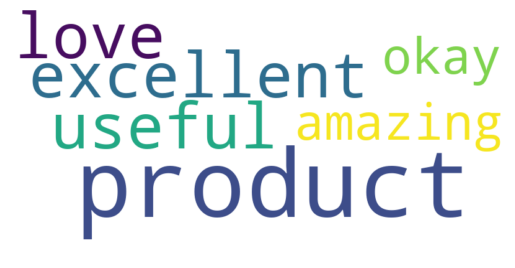

In [11]:
# Q5 

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This product is excellent and very useful.",
    "I love this amazing product.",
    "The product is terrible and disappointing.",
    "The quality is poor and the service is bad.",
    "The product is okay."
]

positive_reviews = []

for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)

    if sentiment == "Positive":
        positive_reviews.append(review)

# Word cloud of positive reviews
all_positive = " ".join(positive_reviews)

wc = WordCloud(width=800, height=400,
               background_color="white").generate(all_positive)

plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

In [13]:
# Q6

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Artificial intelligence is an important technology.
Artificial intelligence helps people solve problems.
Machines learn from data and improve their performance.
Deep learning is used in image recognition.
Natural language processing helps computers understand language.
Technology makes our lives easier and faster.
Students use technology to learn new skills.
Computers can analyze data and find useful patterns.
Artificial intelligence is changing education and healthcare.
Learning technology is useful for future careers.
Data helps machines make better predictions.
Programming teaches students how to solve problems.
Technology continues to improve every day.
"""

# 2. Tokenize text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.strip().split("\n"):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(tokens) + 1):
        sequences.append(tokens[:i])

# Pad sequences
max_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding='pre')

X = sequences[:, :-1]
y = sequences[:, -1]

# 3. Build a simple LSTM model
model = Sequential([
    Embedding(total_words, 10),
    LSTM(50),
    Dense(total_words, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

# Train model
model.fit(X, y, epochs=100, verbose=0)

# 4. Generate text from a seed word
def generate_text(seed, next_words=10):
    for _ in range(next_words):
        tokens = tokenizer.texts_to_sequences([seed])[0]
        tokens = pad_sequences([tokens], maxlen=max_len-1, padding='pre')
        prediction = model.predict(tokens, verbose=0)
        next_index = np.argmax(prediction)
        next_word = tokenizer.index_word.get(next_index, "")
        if not next_word:
            break
        seed += " " + next_word
    return seed

print(generate_text("artificial", 10))
print(generate_text("technology", 10))
print(generate_text("students", 10))

artificial intelligence is is to solve problems image recognition recognition recognition
technology is is data and skills patterns patterns patterns patterns predictions
students intelligence is to to problems improve recognition recognition performance patterns
